# FryWise — train the TPM degradation model

**DEMO ONLY — synthetic data, illustrative parameters. Not for food-safety decisions.**

Goal: learn how many TPM points each kilogram of (stress-weighted) fried food adds, using only what a
restaurant would really have: POS sales, the recipe table, handheld TPM readings and logged oil events.

Model (per vat, between two consecutive valid readings of the same oil batch):

`ΔTPM + dilution_from_top_ups = idle × hot_blocks + k × stress_kg + k × (filter_mult − 1) × stress_kg_while_filtered`

The fitted values are exported to `model/model_params.json` and as a ready-to-paste `MODEL` block for the
Dify code node "② TPM model".

In [1]:
import json
import os

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold

ROOT = os.path.abspath(os.path.join(os.path.dirname(__file__) if "__file__" in globals() else ".", ".."))
if not os.path.exists(os.path.join(ROOT, "data")):
    ROOT = os.path.abspath(".")
DATA = os.path.join(ROOT, "data", "synthetic", "full")
if not os.path.exists(os.path.join(DATA, "pos_items.csv")):
    DATA = os.path.join(ROOT, "data", "synthetic", "sample")
print("Using data from", DATA)

VAT_FAMILY = {"F1": "fries", "C1": "chicken"}
ROUTING_SHARE = 0.5
FRESH_TPM, VAT_VOLUME_L, TOPUP_L, FILTER_BLOCKS = 5.0, 15.0, 2.0, 32

recipe = pd.read_csv(os.path.join(ROOT, "data", "recipe_master.csv"))
pos_items = pd.read_csv(os.path.join(DATA, "pos_items.csv"), parse_dates=["block_start"])
pos_blocks = pd.read_csv(os.path.join(DATA, "pos_blocks.csv"), parse_dates=["block_start"])
readings = pd.read_csv(os.path.join(DATA, "tpm_readings.csv"), parse_dates=["measurement_timestamp"])
events = pd.read_csv(os.path.join(DATA, "oil_events.csv"), parse_dates=["action_timestamp"])
print(len(pos_items), "POS lines,", len(readings), "TPM readings,", len(events), "oil events")

Using data from /home/claude/frywise/data/synthetic/full
230017 POS lines, 2718 TPM readings, 1775 oil events


## 1. POS → stress-weighted fried kg per vat per 15-minute block
Non-fried items (grill) have no fryer family and drop out automatically.

In [2]:
items = pos_items.merge(recipe[["sku", "fryer_family", "fried_g_per_unit", "stress_weight"]],
                        left_on="sku_id", right_on="sku", how="left")
items = items.dropna(subset=["fryer_family"])
items["stress_kg"] = items.quantity * items.fried_g_per_unit / 1000 * items.stress_weight
fam_load = items.groupby(["store_id", "block_start", "fryer_family"]).stress_kg.sum().unstack(fill_value=0.0)

blocks = []
for vat, fam in VAT_FAMILY.items():
    b = pos_blocks[["store_id", "block_start"]].copy()
    b["vat_id"] = vat
    b = b.merge(fam_load[fam].rename("fam_stress").reset_index(), on=["store_id", "block_start"], how="left")
    b["stress_kg"] = b.fam_stress.fillna(0.0) * ROUTING_SHARE
    blocks.append(b.drop(columns="fam_stress"))
blocks = pd.concat(blocks).sort_values(["store_id", "vat_id", "block_start"]).reset_index(drop=True)

# filter effect: active for FILTER_BLOCKS operating blocks after each logged filtration
blocks["filter_active"] = False
for (store, vat), g in blocks.groupby(["store_id", "vat_id"]):
    f_times = events[(events.store_id == store) & (events.vat_id == vat) & (events.action_type == "filter")].action_timestamp
    starts = g.block_start.values
    active = np.zeros(len(g), dtype=bool)
    for ft in f_times.values:
        i0 = np.searchsorted(starts, ft)
        active[i0:i0 + FILTER_BLOCKS] = True
    blocks.loc[g.index, "filter_active"] = active
blocks.head()

,store_id,block_start,vat_id,stress_kg,filter_active
0,S01,2026-01-05 07:00:00,C1,0.44135,False
1,S01,2026-01-05 07:15:00,C1,0.10595,False
2,S01,2026-01-05 07:30:00,C1,0.21335,False
3,S01,2026-01-05 07:45:00,C1,0.32680,False
4,S01,2026-01-05 08:00:00,C1,0.07200,False


## 2. Build training intervals between consecutive valid readings of the same oil batch
Top-ups dilute the oil; we add back the expected dilution using the volume-weighted mixing formula and a
linear interpolation of TPM at the moment of the top-up. Intervals containing a full change are impossible
by construction (a change starts a new oil batch).

In [3]:
valid = readings[readings.measurement_validity_flag == "valid"].sort_values("measurement_timestamp")
rows = []
for (store, vat, batch), g in valid.groupby(["store_id", "vat_id", "oil_batch_id"]):
    g = g.sort_values("measurement_timestamp")
    b = blocks[(blocks.store_id == store) & (blocks.vat_id == vat)]
    ev = events[(events.store_id == store) & (events.vat_id == vat) & (events.oil_batch_id == batch) & (events.action_type == "top_up")]
    for (_, r0), (_, r1) in zip(g.iloc[:-1].iterrows(), g.iloc[1:].iterrows()):
        t0, t1 = r0.measurement_timestamp, r1.measurement_timestamp
        w = b[(b.block_start >= t0) & (b.block_start < t1)]
        tu = ev[(ev.action_timestamp >= t0) & (ev.action_timestamp < t1)]
        dil = 0.0
        for ts in tu.action_timestamp:
            frac = (ts - t0) / (t1 - t0)
            tpm_est = r0.tpm_pct + frac * (r1.tpm_pct - r0.tpm_pct)
            dil += (tpm_est - FRESH_TPM) * TOPUP_L / VAT_VOLUME_L
        rows.append({
            "store_id": store, "vat_id": vat, "oil_batch_id": batch, "t0": t0, "t1": t1,
            "tpm0": r0.tpm_pct, "tpm1": r1.tpm_pct, "y": r1.tpm_pct - r0.tpm_pct + dil,
            "hot_blocks": len(w),
            "stress_kg": w.stress_kg.sum(),
            "stress_kg_filtered": w.loc[w.filter_active, "stress_kg"].sum(),
            "n_top_ups": len(tu),
        })
iv = pd.DataFrame(rows)
iv = iv[iv.hot_blocks > 0]
print(len(iv), "training intervals")
iv.describe().round(2)

2497 training intervals


,t0,t1,tpm0,tpm1,y,hot_blocks,stress_kg,stress_kg_filtered,n_top_ups
count,2497,2497,2497.00,2497.00,2497.00,2497.00,2497.00,2497.00,2497.00
mean,2026-01-20 00:07:27.296756,2026-01-20 05:21:19.175010,14.80,15.84,1.70,15.58,12.71,5.09,0.44
min,2026-01-05 07:15:00,2026-01-05 11:00:00,4.10,4.90,-0.90,7.00,0.84,0.00,0.00
25%,2026-01-12 11:00:00,2026-01-12 19:00:00,10.70,11.90,0.90,14.00,6.47,0.00,0.00
50%,2026-01-19 22:30:00,2026-01-20 07:15:00,15.00,16.10,1.60,15.00,12.03,0.00,0.00
75%,2026-01-27 11:00:00,2026-01-27 15:00:00,19.10,19.90,2.33,16.00,17.16,11.26,1.00
max,2026-02-03 19:00:00,2026-02-03 22:30:00,24.40,27.40,7.03,61.00,52.96,44.27,3.00
std,NaN,NaN,5.23,4.94,1.17,6.15,8.04,7.07,0.53


## 3. Fit per vat, validated with store-grouped cross-validation
Rows from the same store never appear in both train and test folds (README §8.3).

In [4]:
FEATURES = ["hot_blocks", "stress_kg", "stress_kg_filtered"]
results, params = {}, {}
for vat in VAT_FAMILY:
    d = iv[iv.vat_id == vat].reset_index(drop=True)
    X, y, groups = d[FEATURES].values, d.y.values, d.store_id.values
    n_splits = min(5, len(np.unique(groups)))
    maes, base_maes = [], []
    if n_splits >= 2:
        for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
            m = LinearRegression(fit_intercept=False).fit(X[tr], y[tr])
            maes.append(np.mean(np.abs(m.predict(X[te]) - y[te])))
            rate = y[tr].sum() / d.hot_blocks.values[tr].sum()          # baseline: time-only model
            base_maes.append(np.mean(np.abs(rate * d.hot_blocks.values[te] - y[te])))
    m = LinearRegression(fit_intercept=False).fit(X, y)
    idle, k, kf = m.coef_
    resid = y - m.predict(X)
    meas_var = 2 * 0.4 ** 2                                              # two readings, Testo-like noise
    sd_block = float(np.sqrt(max(np.var(resid) - meas_var, 1e-4) / d.hot_blocks.mean()))
    params[vat] = {"idle": idle, "k": k, "filter_mult": 1 + kf / k, "sd_block": sd_block}
    results[vat] = {"n_intervals": len(d), "cv_mae_tpm": np.mean(maes) if maes else None,
                    "baseline_time_only_mae": np.mean(base_maes) if base_maes else None}
pd.DataFrame(params).T.round(4), pd.DataFrame(results).T.round(3)

(      idle       k  filter_mult  sd_block
 F1  0.0224  0.0974       0.8331    0.0661
 C1  0.0129  0.1445       0.8680    0.0435,
     n_intervals  cv_mae_tpm  baseline_time_only_mae
 F1       1249.0       0.493                   0.654
 C1       1248.0       0.479                   0.709)

## 4. Historical demand profile and export
The forecast in Dify needs the typical orders per 15 minutes by hour and the average stress-kg per order.

In [5]:
pb = pos_blocks.copy()
pb["hour"] = pb.block_start.dt.hour
hist_orders = pb.groupby("hour").n_orders.mean().round(1)
total_orders = pos_blocks.n_orders.sum()
fam_total = items.groupby("fryer_family").stress_kg.sum()
hist_stress = (fam_total / total_orders).round(4)

MODEL = {
    "version": "trained-synthetic-%s" % pd.Timestamp.now().strftime("%Y%m%d"),
    "vat_family": VAT_FAMILY,
    "routing_share": {v: ROUTING_SHARE for v in VAT_FAMILY},
    "k_tpm_per_stress_kg": {v: round(params[v]["k"], 4) for v in VAT_FAMILY},
    "idle_tpm_per_block": round(float(np.mean([params[v]["idle"] for v in VAT_FAMILY])), 4),
    "resid_sd_per_block": round(float(np.mean([params[v]["sd_block"] for v in VAT_FAMILY])), 4),
    "capacity_stress_kg_per_block": {"F1": 10.0, "C1": 8.0},
    "filter_rate_multiplier": round(float(np.clip(np.mean([params[v]["filter_mult"] for v in VAT_FAMILY]), 0.5, 1.0)), 3),
    "filter_effect_blocks": FILTER_BLOCKS,
    "fresh_tpm": FRESH_TPM,
    "vat_volume_l": {v: VAT_VOLUME_L for v in VAT_FAMILY},
    "hist_orders_per_block": {int(h): float(v) for h, v in hist_orders.items()},
    "hist_stress_kg_per_order": {f: float(v) for f, v in hist_stress.items()},
    "peak_orders": 30,
    "quiet_orders": 15,
    "horizon_blocks": 204,
}
os.makedirs(os.path.join(ROOT, "model"), exist_ok=True)
with open(os.path.join(ROOT, "model", "model_params.json"), "w") as f:
    json.dump({"MODEL": MODEL, "validation": results}, f, indent=2, default=float)
def plain(o):
    """Convert numpy scalars to plain Python so the block pastes cleanly into Dify (int hour keys kept)."""
    if isinstance(o, dict):
        return {(int(k) if isinstance(k, (np.integer,)) else k): plain(v) for k, v in o.items()}
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    return o


import pprint
with open(os.path.join(ROOT, "model", "MODEL_block_for_dify.py"), "w") as f:
    f.write("# Paste this over the MODEL = {...} block in Dify code node '② TPM model'\n")
    f.write("MODEL = " + pprint.pformat(plain(MODEL), indent=4, width=110, sort_dicts=False) + "\n")
print(json.dumps(MODEL, indent=2))

{
  "version": "trained-synthetic-20261117",
  "vat_family": {
    "F1": "fries",
    "C1": "chicken"
  },
  "routing_share": {
    "F1": 0.5,
    "C1": 0.5
  },
  "k_tpm_per_stress_kg": {
    "F1": 0.0974,
    "C1": 0.1445
  },
  "idle_tpm_per_block": 0.0176,
  "resid_sd_per_block": 0.0548,
  "capacity_stress_kg_per_block": {
    "F1": 10.0,
    "C1": 8.0
  },
  "filter_rate_multiplier": 0.851,
  "filter_effect_blocks": 32,
  "fresh_tpm": 5.0,
  "vat_volume_l": {
    "F1": 15.0,
    "C1": 15.0
  },
  "hist_orders_per_block": {
    "7": 7.9,
    "8": 11.9,
    "9": 9.9,
    "10": 11.8,
    "11": 23.9,
    "12": 39.3,
    "13": 33.6,
    "14": 17.8,
    "15": 11.9,
    "16": 14.0,
    "17": 25.7,
    "18": 37.6,
    "19": 29.7,
    "20": 19.8,
    "21": 15.9,
    "22": 11.9,
    "23": 8.0
  },
  "hist_stress_kg_per_order": {
    "chicken": 0.0767,
    "fries": 0.0893
  },
  "peak_orders": 30,
  "quiet_orders": 15,
  "horizon_blocks": 204
}


## 5. Sanity check against the simulator's hidden truth
Only possible with synthetic data: the simulator used idle = 0.020, k(F1) = 0.100, k(C1) = 0.130,
filter multiplier = 0.85 (store-level effects vary around these). POS misses ~5 % waste/remakes,
so k is expected to come out slightly higher than the hidden value.

In [6]:
truth = {"F1": {"idle": 0.020, "k": 0.100, "filter_mult": 0.85}, "C1": {"idle": 0.020, "k": 0.130, "filter_mult": 0.85}}
pd.DataFrame({v: {**{"fit_" + a: round(params[v][a], 4) for a in ("idle", "k", "filter_mult")},
                  **{"true_" + a: b for a, b in truth[v].items()}} for v in VAT_FAMILY}).T

,fit_idle,fit_k,fit_filter_mult,true_idle,true_k,true_filter_mult
F1,0.0224,0.0974,0.8331,0.02,0.10,0.85
C1,0.0129,0.1445,0.8680,0.02,0.13,0.85


## 6. Picture of one oil lifecycle (synthetic)
Hidden true TPM (line), handheld readings (dots), top-ups, filters and full changes.

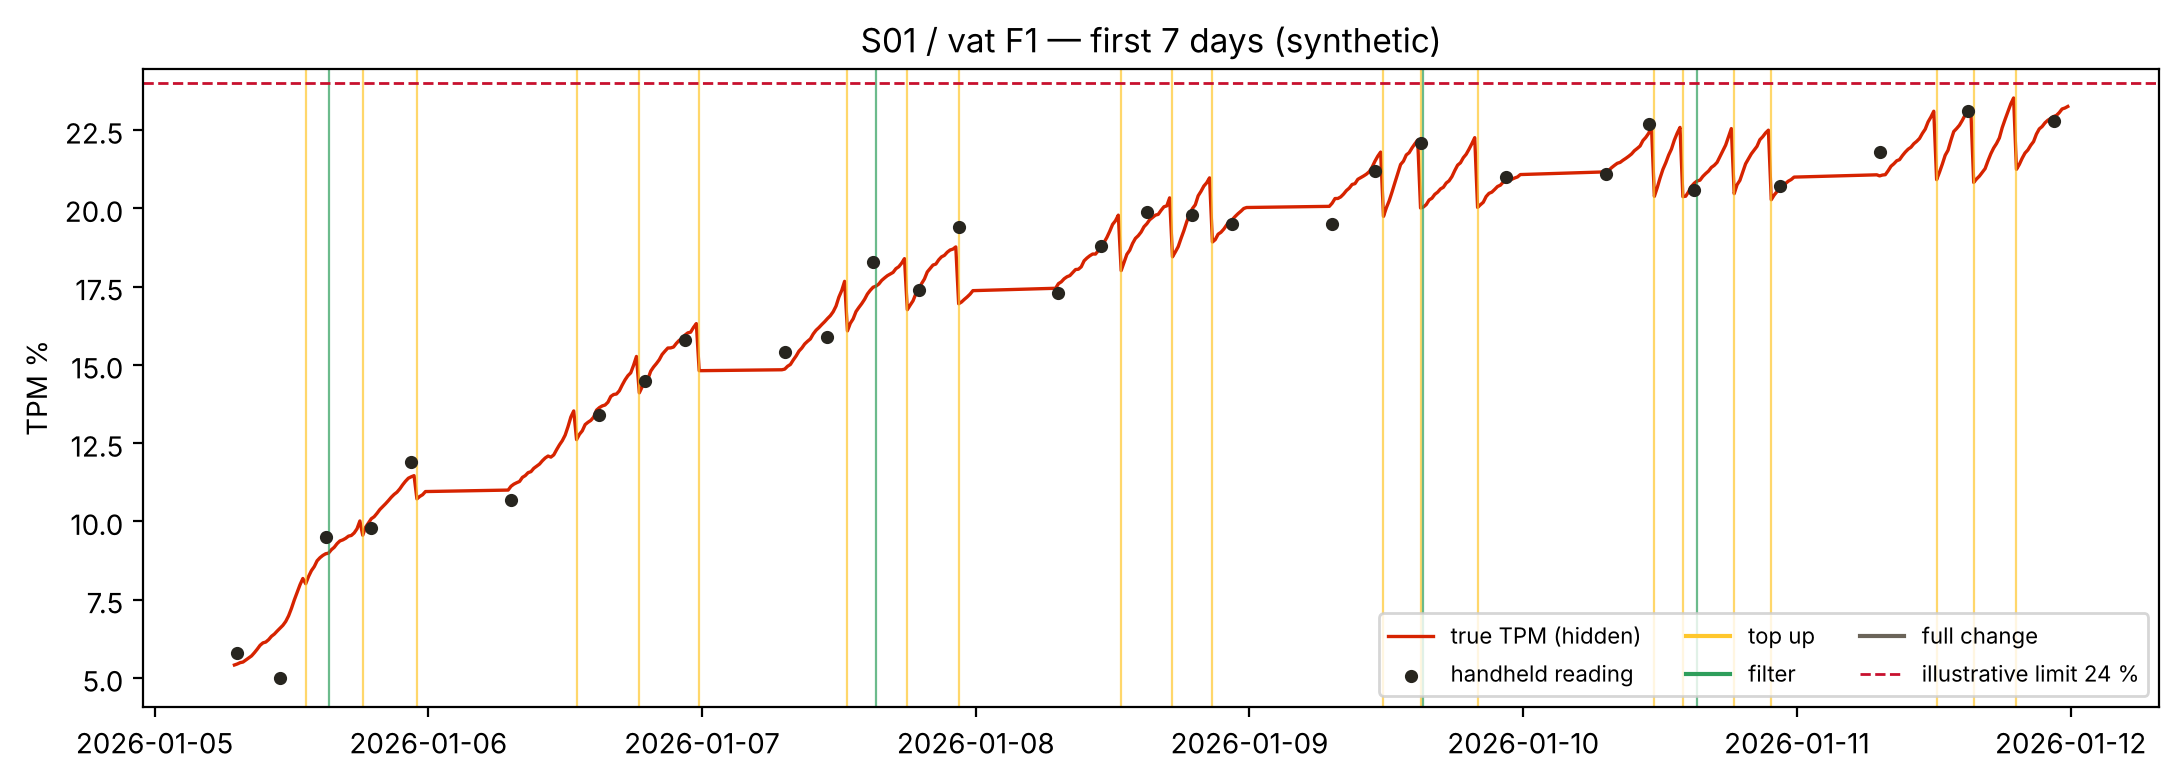

In [7]:
import matplotlib
import matplotlib.pyplot as plt

truth_df = pd.read_csv(os.path.join(DATA, "tpm_truth.csv"), parse_dates=["block_start"])
store, vat = sorted(truth_df.store_id.unique())[0], "F1"
t = truth_df[(truth_df.store_id == store) & (truth_df.vat_id == vat)]
t = t[t.block_start < t.block_start.min() + pd.Timedelta(days=7)]
r = readings[(readings.store_id == store) & (readings.vat_id == vat) & (readings.measurement_timestamp <= t.block_start.max())]
e = events[(events.store_id == store) & (events.vat_id == vat) & (events.action_timestamp <= t.block_start.max())]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t.block_start, t.true_tpm_end, color="#D62300", lw=1.2, label="true TPM (hidden)")
ax.scatter(r.measurement_timestamp, r.tpm_pct, color="#27251F", s=14, zorder=3, label="handheld reading")
for kind, c in [("top_up", "#FFC72C"), ("filter", "#2E9E5B"), ("full_change", "#6B6459")]:
    for ts in e[e.action_type == kind].action_timestamp:
        ax.axvline(ts, color=c, lw=0.8, alpha=0.7)
    ax.plot([], [], color=c, label=kind.replace("_", " "))
ax.axhline(24, color="#C8102E", ls="--", lw=1, label="illustrative limit 24 %")
ax.set_ylabel("TPM %"); ax.set_title("%s / vat %s — first 7 days (synthetic)" % (store, vat))
ax.legend(ncol=3, fontsize=8, loc="lower right"); fig.tight_layout()
os.makedirs(os.path.join(ROOT, "docs", "screenshots"), exist_ok=True)
fig.savefig(os.path.join(ROOT, "docs", "screenshots", "synthetic_oil_lifecycle.png"), dpi=120)